In [66]:
# Imports
import numpy as np
import matplotlib
from matplotlib import pyplot as plt
%matplotlib inline
import sklearn
import pandas as pd
from scipy import signal
import seaborn as sns
import scipy
import numpy.ma as ma

import netCDF4 as nc
from netCDF4 import Dataset
import xarray as xr
import geopandas as gpd
import regionmask
import cartopy.feature as cfeature
import cartopy.crs as ccrs
import matplotlib.ticker as mticker

import tigramite
from tigramite import data_processing as pp
from tigramite.toymodels import structural_causal_processes as toys
from tigramite import plotting as tp
from tigramite.pcmci import PCMCI
from tigramite.lpcmci import LPCMCI

from tigramite.independence_tests.parcorr import ParCorr
from tigramite.independence_tests.robust_parcorr import RobustParCorr
from tigramite.independence_tests.gpdc import GPDC
from tigramite.independence_tests.cmiknn import CMIknn

from tigramite.models import LinearMediation, Prediction

from scipy.stats import ttest_1samp

## define PCMCI+ function

In [2]:
path = '/Users/ernest/Research/thesis/_paper_/'

In [3]:
# prescribe links (we are only interested in evaluating AMOC->PREC and AMOC->NDVI)
all_parents = {0: [(0, -1)], 
 1: [(1, -1), (1, -2), (0, -2)], 
 2: [(1, -1), (0, -2)], 
 3: [(3, -1), (2, -1)]}

In [4]:
df = pd.read_csv(path + 'data/ERA5_1982-2022.csv', index_col=[0])

list(df.columns)

['time',
 'AMOC_era5',
 'AMOC_hadcrut5',
 'AMOC_hadsst4',
 'AMOC_cobe',
 'AMOC_ersst',
 'CLLJ',
 'SAR_prec',
 'NDVI',
 'Southern AR dry season']

In [5]:
def getgraph_fixed(df, variables, index_selection, all_parents, tau_min, tau_max):

    CE = []
    df = df
    
    test = df[variables]
    index_selection = index_selection
    
    data = np.array(test)
    
    mask_key = 'Southern AR dry season'
    mask = df[[f'{mask_key}', f'{mask_key}', f'{mask_key}', f'{mask_key}']]
    data_mask = np.array(mask)
    
    T, N = data.shape
    # Initialize dataframe object, specify time axis and variable names
    names = index_selection
    dataframe = pp.DataFrame(data, 
                         mask=data_mask,
                         datatime = {0:np.arange(len(data))}, 
                         var_names=names)

    med = LinearMediation(dataframe=dataframe,
            mask_type = 'y')
    med.fit_model(all_parents = all_parents, tau_max=tau_max) 
    Links = med.get_val_matrix()
    return med

In [6]:
def cee(df, variables, index_selection, all_parents):

    AMOC_PREC = []
    AMOC_PREC_direct = []
    AMOC_NDVI = []
    CLLJ_PREC = []
    PREC_NDVI = []

    med = getgraph_fixed(df, variables, index_selection, all_parents, 0, 5)
    AMOC_PREC.append(med.get_ce(i=0, tau=-3, j=2))
    AMOC_PREC_direct.append(med.get_ce(i=0, tau=-2, j=2))
    AMOC_NDVI.append(med.get_ce(i=0, tau=-4, j=3))
    CLLJ_PREC.append(med.get_ce(i=1, tau=-1, j=2))
    PREC_NDVI.append(med.get_ce(i=2, tau=-1, j=3))

    return AMOC_PREC, AMOC_PREC_direct, AMOC_NDVI, CLLJ_PREC, PREC_NDVI

## initialise data

In [7]:
precip = xr.open_dataset(path + 'data/AR/prec/ERA5_south.nc')
ndvi = xr.open_dataset(path + 'data/AR/ndvi/south.nc4')
sar_shp = gpd.read_file(path + 'data/shapefiles/southernAR.shp')

In [8]:
# unify time grid
ndvi['time'] = pd.to_datetime(ndvi['time'])
precip['time'] = pd.to_datetime(precip['time'])

# Resample the DataFrame to reduce time resolution to one entry per month
ndvi_monthly = ndvi.resample({'time': 'M'}).mean()

In [9]:
prec = precip.loc[dict(time=slice('1982-01-01', '2022-12-01'))]

In [10]:
ndvi_grid = ndvi_monthly.interp(lat=prec['latitude'], lon=prec['longitude'])

## loop through grid-cells and run PCMCI+

In [11]:
def causal_map(prec, ndvi_monthly, df, cee, all_parents, amoc_index):
    lat_prec = prec['latitude']
    lon_prec = prec['longitude']
    lat_ndvi = ndvi_monthly['latitude']
    lon_ndvi = ndvi_monthly['longitude']
    time_cycle = 12

    # Create an empty dataset to store the results
    output_ds = xr.Dataset(
        {   
            'CE_amocprec': (['latitude', 'longitude'], np.full((len(lat_prec), len(lon_prec)), np.nan)),
            'CE_prec': (['latitude', 'longitude'], np.full((len(lat_prec), len(lon_prec)), np.nan)),
            'CE_ndvi': (['latitude', 'longitude'], np.full((len(lat_prec), len(lon_prec)), np.nan)),
            'CE_clljprec': (['latitude', 'longitude'], np.full((len(lat_prec), len(lon_prec)), np.nan)),
            'CE_precndvi': (['latitude', 'longitude'], np.full((len(lat_prec), len(lon_prec)), np.nan))
        },
        coords={
            'latitude': lat_prec,
            'longitude': lon_prec
        }
    )

    # Define custom function
    def cee_gc(ts1, ts2):
        variables = ['AMOC_sst', 'CLLJ', 'SAR_prec', 'SAR_ndvi']
        index_selection = ['AMOC', 'CLLJ', 'PREC', 'NDVI']
        
        if np.isnan(ts1).all() or np.isnan(ts2).all():
            return np.nan, np.nan
        else:
            new_df = pd.DataFrame({
                'time': df['time'],
                'AMOC_sst': df[amoc_index],  # Use the specified AMOC index
                'CLLJ': df['CLLJ'],
                'Southern AR dry season': df['Southern AR dry season'],
                'SAR_prec': ts1,
                'SAR_ndvi': ts2
            })
            
            result1, result2, result3, result4, result5 = cee(new_df, variables, index_selection, all_parents)
            return result1, result2, result3, result4, result5

    # Loop through each grid cell
    for i in range(len(lat_prec)):
        for j in range(len(lon_prec)):
            ts1_pre = prec.isel(latitude=i, longitude=j)['tp']  # Adjust variable name (from the `prec` dataset)
            ts2_pre = ndvi_monthly.isel(latitude=i, longitude=j)['ndvi']  # Adjust variable name (from the `ndvi_monthly` dataset)
        
            # Only perform the calculation if there are valid values in both time series
            if not (np.isnan(ts1_pre).all() or np.isnan(ts2_pre).all()):
                # Detrend
                ts1 = ts1_pre.copy()
                ts2 = ts2_pre.copy()
                for k in range(time_cycle):
                    ts1[k::time_cycle] = scipy.signal.detrend(ts1_pre[k::time_cycle], axis=0)
                    ts2[k::time_cycle] = scipy.signal.detrend(ts2_pre[k::time_cycle], axis=0)
                
                result1, result2, result3, result4, result5 = cee_gc(ts1, ts2)
                output_ds['CE_prec'][i, j] = result1[0]
                output_ds['CE_amocprec'][i, j] = result2[0]
                output_ds['CE_ndvi'][i, j] = result3[0]
                output_ds['CE_clljprec'][i, j] = result4[0]
                output_ds['CE_precndvi'][i, j] = result5[0]

    # Return the resulting dataset
    return output_ds

In [13]:
CM_era5 = causal_map(prec, ndvi_grid, df, cee, all_parents, 'AMOC_era5')
CM_hadcrut5 = causal_map(prec, ndvi_grid, df, cee, all_parents, 'AMOC_hadcrut5')
CM_hadsst4 = causal_map(prec, ndvi_grid, df, cee, all_parents, 'AMOC_hadsst4')
CM_cobe = causal_map(prec, ndvi_grid, df, cee, all_parents, 'AMOC_cobe')
CM_ersst = causal_map(prec, ndvi_grid, df, cee, all_parents, 'AMOC_ersst')

In [14]:
CM_list = [
    CM_era5,
    CM_hadcrut5,
    CM_hadsst4,
    CM_cobe,
    CM_ersst
]

In [36]:
tick_format = mticker.FuncFormatter(lambda x, _: f"{x:.1f}")

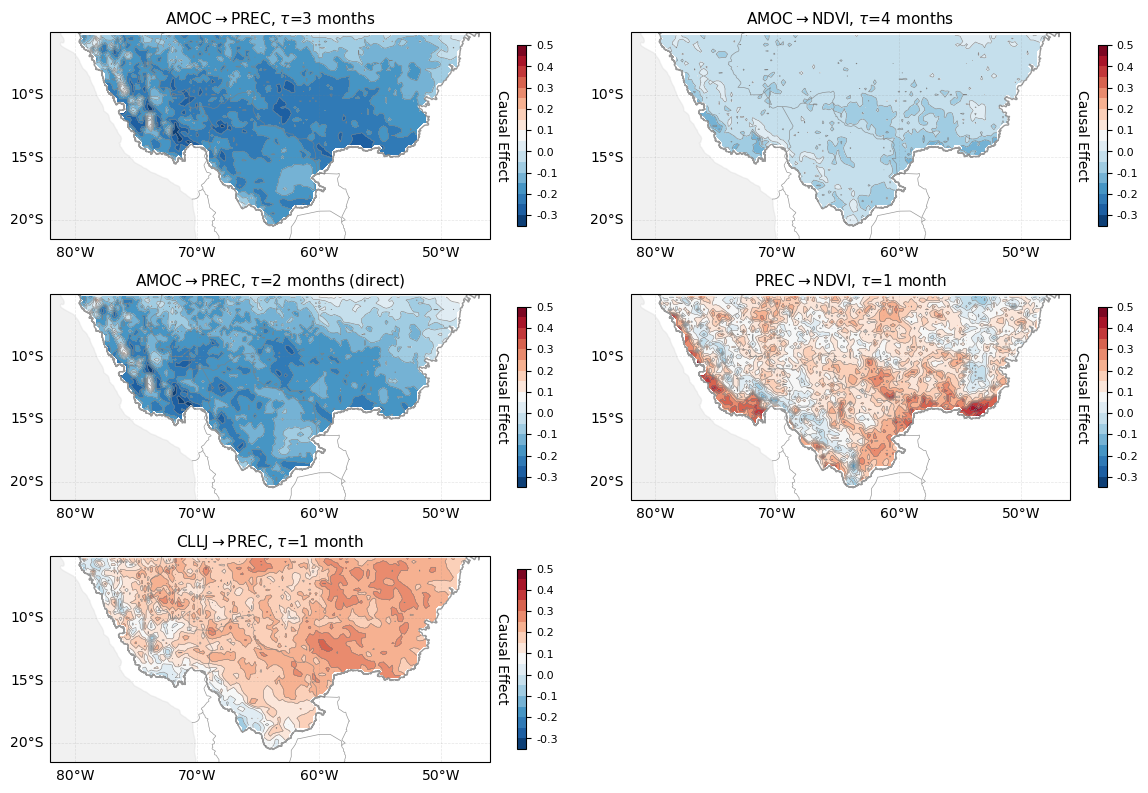

In [161]:
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 8), 
                         subplot_kw={'projection': ccrs.PlateCarree(central_longitude=-60)})

axes = axes.flatten()

variables = ['CE_prec', 'CE_ndvi', 'CE_amocprec', 'CE_precndvi', 'CE_clljprec']

titles = {
    'CE_prec': r'AMOC$\rightarrow$PREC, $\tau$=3 months',
    'CE_ndvi': r'AMOC$\rightarrow$NDVI, $\tau$=4 months',
    'CE_amocprec': r'AMOC$\rightarrow$PREC, $\tau$=2 months (direct)',
    'CE_precndvi': r'PREC$\rightarrow$NDVI, $\tau$=1 month',
    'CE_clljprec': r'CLLJ$\rightarrow$PREC, $\tau$=1 month'
}

vmin = -0.35
vmax = 0.5

# Define contour levels based on vmin and vmax
contour_levels = np.linspace(vmin, vmax, 18)  # 14 levels from vmin to vmax

for i, var in enumerate(variables):
    axes[i].add_feature(cfeature.LAND, color='None')
    axes[i].add_feature(cfeature.OCEAN, color='lightgrey', alpha=.3)
    axes[i].add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='grey', alpha=.8)  # Country borders

    # Create the filled contour plot with common vmin and vmax
    img = axes[i].contourf(CM_list[4].longitude, CM_list[4].latitude, CM_list[4][var],
                           levels=contour_levels, transform=ccrs.PlateCarree(), 
                           cmap='RdBu_r', vmin=vmin, vmax=vmax)
    
    # Create contour lines with the same levels for consistency
    contour_lines = axes[i].contour(CM_list[4].longitude, CM_list[4].latitude, CM_list[4][var],
                                    levels=np.linspace(vmin, vmax, 18),
                                    colors='grey', linewidths=0.4, linestyles='solid', 
                                    transform=ccrs.PlateCarree())

    sar_shp.boundary.plot(ax=axes[i], transform=ccrs.PlateCarree(), edgecolor='grey', linewidth=1, alpha=.8)

    # Add titles, colorbars, etc., as before
    axes[i].set_title(titles[var], size=11)
    
    axes[i].set_xlim(-22, 14)  # Set longitude limits (for example, from -180° to 180°)
    axes[i].set_ylim(-21.5, -5)    # Set latitude limits (for example, from -60° to 60°)

    # Add colorbar for the filled contour
    cbar = plt.colorbar(img, ax=axes[i], orientation='vertical', shrink=0.8)
    cbar.set_label("Causal Effect", labelpad=-35, rotation=270)
    cbar.formatter = tick_format
    cbar.update_ticks()
    cbar.ax.tick_params(labelsize=8)

    # Add gridlines with customized intervals for latitude and longitude
    gridlines = axes[i].gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.2, linestyle='--')
    gridlines.right_labels = False
    gridlines.top_labels = False
    gridlines.xlocator = mticker.FixedLocator(range(-180, 181, 10))  # Set longitude gridlines every 10°
    gridlines.ylocator = mticker.FixedLocator(range(-90, 91, 5))    # Set latitude gridlines every 5°


# Remove empty subplots
if len(variables) < len(axes):
    for j in range(len(variables), len(axes)):
        fig.delaxes(axes[j])  # Remove the empty axes

# Final layout adjustments if necessary
plt.tight_layout()

plt.savefig(path + 'figures/causal_maps/contour_ersst.png', dpi=300, bbox_inches='tight')

## Agreement

In [48]:
np.unique(agreement_score)

array([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.])

## agreement relative to ERA5 baseline

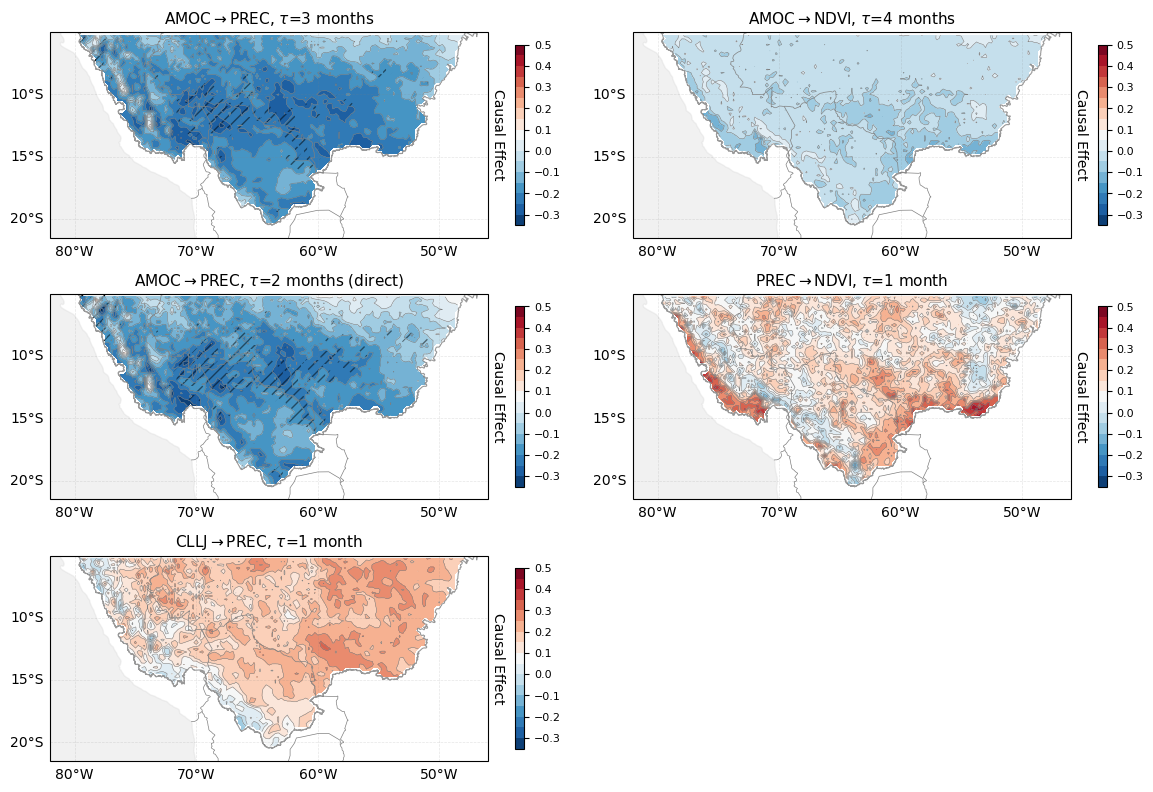

In [172]:
import cartopy.feature as cfeature

# Define variables, titles, and individual thresholds for each variable
variables = ['CE_prec', 'CE_ndvi', 'CE_amocprec', 'CE_precndvi', 'CE_clljprec']
titles = {
    'CE_prec': r'AMOC$\rightarrow$PREC, $\tau$=3 months',
    'CE_ndvi': r'AMOC$\rightarrow$NDVI, $\tau$=4 months',
    'CE_amocprec': r'AMOC$\rightarrow$PREC, $\tau$=2 months (direct)',
    'CE_precndvi': r'PREC$\rightarrow$NDVI, $\tau$=1 month',
    'CE_clljprec': r'CLLJ$\rightarrow$PREC, $\tau$=1 month'
}

# Define global vmin and vmax
vmin = -0.35
vmax = 0.5
contour_levels = np.linspace(vmin, vmax, 18)  # 7 levels from vmin to vmax

# Thresholds for each variable based on bootstrapped standard deviations
thresholds = {
    'CE_prec': 2*0.015047,
    'CE_ndvi': 2*0.010285,
    'CE_amocprec': 2*0.017515,
    'CE_precndvi': 2*0.016012,
    'CE_clljprec': 2*0.024951
}

# Set up subplots
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(12, 8), 
                         subplot_kw={'projection': ccrs.PlateCarree(central_longitude=-60)})
axes = axes.flatten()

# Loop through each variable
for i, var in enumerate(variables):
    # Add land and ocean features
    axes[i].add_feature(cfeature.LAND, color='None')
    axes[i].add_feature(cfeature.OCEAN, color='lightgrey', alpha=.3)
    axes[i].add_feature(cfeature.BORDERS, linewidth=0.5, edgecolor='grey', alpha=1)  # Country borders

    # Create the filled contour plot for the baseline data with common vmin and vmax
    img = axes[i].contourf(CM_list[0].longitude, CM_list[0].latitude, CM_list[0][var],
                           levels=contour_levels, transform=ccrs.PlateCarree(), 
                           cmap='RdBu_r', vmin=vmin, vmax=vmax)
    
    # Add contour lines for baseline data
    contour_lines = axes[i].contour(CM_list[0].longitude, CM_list[0].latitude, CM_list[0][var],
                                     levels=np.linspace(vmin, vmax, 18), colors='grey', linewidths=0.4,
                                     linestyles='solid',
                                     transform=ccrs.PlateCarree())

    # Initialize agreement score
    agreement_score = np.zeros(CM_list[0][var].shape, dtype=int)  # Match baseline data's shape
    threshold = thresholds[var]
    baseline = CM_list[0][var]
    lower_bound = baseline - threshold
    upper_bound = baseline + threshold

    # Track cells where all datasets are NaN
    all_nan_mask = np.ones(CM_list[0][var].shape, dtype=bool)

    # Iterate over other datasets and check for agreement with baseline
    for ds in CM_list[1:]:
        data_array = ds[var].squeeze()
        
        # Update all_nan_mask by checking NaN values in the current dataset
        all_nan_mask &= np.isnan(data_array)

        # Check if data points are within the agreement bounds
        within_bounds = (data_array >= lower_bound) & (data_array <= upper_bound)
        
        # Increment agreement score where within bounds
        agreement_score += within_bounds.astype(int)
        
    # Use np.where to assign agreement score of 4 where all datasets are NaN
    agreement_score = np.where(all_nan_mask, 4, agreement_score)

    # Create an agreement mask where fewer than X datasets agree with the baseline
    low_agreement_mask = (agreement_score < 2).astype(int)
    
    # Overlay shading where the low agreement mask is True
    axes[i].contourf(CM_list[0].longitude, CM_list[0].latitude,
                     low_agreement_mask, levels=[0.5, 1], transform=ccrs.PlateCarree(),
                     colors='none', hatches=['///'], alpha=0)

    # Create the filled contour plot for the baseline data with common vmin and vmax
    img2 = axes[i].contourf(CM_list[0].longitude, CM_list[0].latitude, CM_list[0][var],
                           levels=contour_levels, transform=ccrs.PlateCarree(), 
                           cmap='RdBu_r', vmin=vmin, vmax=vmax, alpha=.5)
    
    # Add shape boundary
    sar_shp.boundary.plot(ax=axes[i], transform=ccrs.PlateCarree(), edgecolor='grey', linewidth=0.8, alpha=.8)

    # Add title and colorbar
    axes[i].set_title(titles[var], size=11)

    axes[i].set_xlim(-22, 14)  # Set longitude limits (for example, from -180° to 180°)
    axes[i].set_ylim(-21.5, -5)    # Set latitude limits (for example, from -60° to 60°)

    cbar = plt.colorbar(img, ax=axes[i], orientation='vertical', shrink=0.8)
    cbar.set_label("Causal Effect", labelpad=-40, rotation=270)
    cbar.ax.tick_params(labelsize=8)

    # Add gridlines with customized intervals for latitude and longitude
    gridlines = axes[i].gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.2, linestyle='--')
    gridlines.right_labels = False
    gridlines.top_labels = False
    gridlines.xlocator = mticker.FixedLocator(range(-180, 181, 10))  # Set longitude gridlines every 10°
    gridlines.ylocator = mticker.FixedLocator(range(-90, 91, 5))     # Set latitude gridlines every 5°

# Remove empty subplots if necessary
if len(variables) < len(axes):
    for j in range(len(variables), len(axes)):
        fig.delaxes(axes[j])

# Final layout adjustments
plt.tight_layout()

plt.savefig(path + 'figures/Figure_4-<2-2std.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()